In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, WhiteKernel, ConstantKernel as C
from sklearn.preprocessing import StandardScaler

np.random.seed(42)

In [2]:
feature_cols = ['CuCl^-1', 'Cu^+2', 'Cl^-1', 'Na^+1', 'K^+1','NO3^-1', 'Fe(CN)6^-4', 'Fe(CN)6^-3', 'T']

df_eta_rho_Aw = pd.read_csv('Data/Coltera_TREC_Eta_rho_Aw.csv').drop(columns='Electrolyte')
df_Cp = pd.read_csv('Data/Coltera_TREC_Cp.csv').drop(columns='Electrolyte')

X_eta_rho_Aw = df_eta_rho_Aw[feature_cols].values
X_Cp = df_Cp[feature_cols].values

print('Eta rho Aw rows:', len(df_eta_rho_Aw))
print('Cp rows:', len(df_Cp))
print('Number of features:', len(feature_cols))

Eta rho Aw rows: 24
Cp rows: 28
Number of features: 9


In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_eta_rho_Aw)

kernel = (C(1.0, (1e-5, 1e5))
          * Matern(length_scale=[1.0]*len(feature_cols), length_scale_bounds=(1e-2, 1e7), nu=1.5)
          + WhiteKernel(noise_level=1e-2, noise_level_bounds=(1e-5, 1.0)))

gp_eta = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=20, random_state=42)
gp_rho = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=20, random_state=42)
gp_Aw = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=20, random_state=42)

gp_eta.fit(X_scaled, np.log(df_eta_rho_Aw['eta'].values + 1e-9))
gp_rho.fit(X_scaled, np.log(df_eta_rho_Aw['rho'].values + 1e-9))
gp_Aw.fit(X_scaled, df_eta_rho_Aw['Aw'].values)

X_new = np.random.uniform(X_eta_rho_Aw.min(axis=0), X_eta_rho_Aw.max(axis=0), size=(1000, len(feature_cols)))
X_new_scaled = scaler.transform(X_new)

eta_log, s_eta = gp_eta.predict(X_new_scaled, return_std=True)
rho_log, s_rho = gp_rho.predict(X_new_scaled, return_std=True)
Aw, s_Aw = gp_Aw.predict(X_new_scaled, return_std=True)

syn = pd.DataFrame(X_new, columns=feature_cols)
syn['eta'] = np.exp(eta_log)
syn['rho'] = np.exp(rho_log)
syn['Aw'] = Aw
syn['s_eta'] = s_eta
syn['s_rho'] = s_rho
syn['s_Aw'] = s_Aw

# keep the 60% of points with the smallest total uncertainty
total = syn['s_eta'] + syn['s_rho'] + syn['s_Aw']
syn = syn[total < total.quantile(0.60)]

print('Rows kept:', len(syn))
#syn.to_csv('synthetic_eta_rho_Aw.csv', index=False)

C:\Users\Dimitris\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 10000000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\Users\Dimitris\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 10000000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\Users\Dimitris\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 4 of parameter k1__k2__length_scale is close to the specified upper bound 10000000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


Rows kept: 600


C:\Users\Dimitris\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 10000000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\Users\Dimitris\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 10000000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\Users\Dimitris\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 4 of parameter k1__k2__length_scale is close to the specified upper bound 10000000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\Users\Dimitris\anaconda3\Lib\site-packages\sklear

In [4]:
scaler_Cp = StandardScaler()
X_Cp_scaled = scaler_Cp.fit_transform(X_Cp)

kernel_Cp = (C(1.0, (1e-5, 1e5))
             * Matern(length_scale=[1.0]*len(feature_cols), length_scale_bounds=(1e-2, 1e7), nu=1.5)
             + WhiteKernel(noise_level=1e-2, noise_level_bounds=(1e-5, 1.0)))

gp_Cp = GaussianProcessRegressor(kernel=kernel_Cp, n_restarts_optimizer=20, random_state=42)
gp_Cp.fit(X_Cp_scaled, df_Cp['Cp'].values)

X_new_Cp = np.random.uniform(X_Cp.min(axis=0), X_Cp.max(axis=0), size=(1000, len(feature_cols)))
Cp, s_Cp = gp_Cp.predict(scaler_Cp.transform(X_new_Cp), return_std=True)

syn_Cp = pd.DataFrame(X_new_Cp, columns=feature_cols)
syn_Cp['Cp'] = Cp
syn_Cp['s_Cp'] = s_Cp

# keep the 60% of points with the smallest uncertainty
syn_Cp = syn_Cp[syn_Cp['s_Cp'] < syn_Cp['s_Cp'].quantile(0.60)]

print('Rows kept:', len(syn_Cp))
#syn_Cp.to_csv('synthetic_Cp.csv', index=False)

Rows kept: 600


C:\Users\Dimitris\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 6 of parameter k1__k2__length_scale is close to the specified upper bound 10000000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


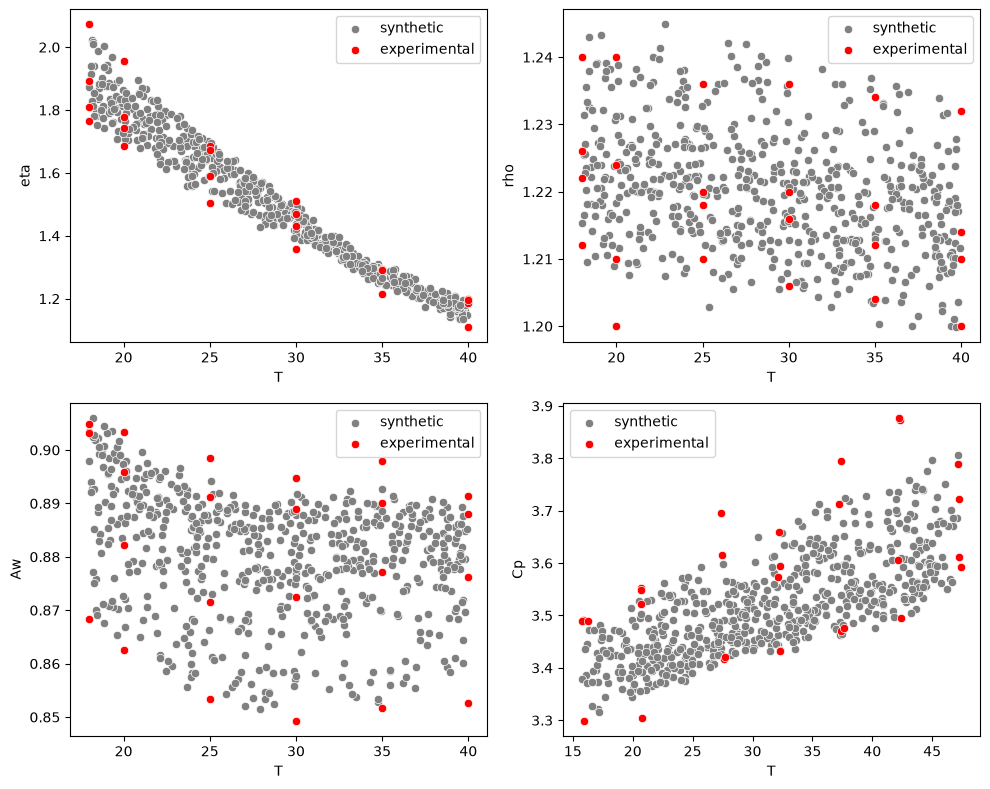

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

sns.scatterplot(x=syn['T'], y=syn['eta'], ax=axes[0, 0], color='grey', label='synthetic')
sns.scatterplot(x=df_eta_rho_Aw['T'], y=df_eta_rho_Aw['eta'], ax=axes[0, 0], color='red', label='experimental')

sns.scatterplot(x=syn['T'], y=syn['rho'], ax=axes[0, 1], color='grey', label='synthetic')
sns.scatterplot(x=df_eta_rho_Aw['T'], y=df_eta_rho_Aw['rho'], ax=axes[0, 1], color='red', label='experimental')

sns.scatterplot(x=syn['T'], y=syn['Aw'], ax=axes[1, 0], color='grey', label='synthetic')
sns.scatterplot(x=df_eta_rho_Aw['T'], y=df_eta_rho_Aw['Aw'], ax=axes[1, 0], color='red', label='experimental')

sns.scatterplot(x=syn_Cp['T'], y=syn_Cp['Cp'], ax=axes[1, 1], color='grey', label='synthetic')
sns.scatterplot(x=df_Cp['T'], y=df_Cp['Cp'], ax=axes[1, 1], color='red', label='experimental')

plt.tight_layout()
plt.show()